# Classificação de Dígitos no SVHN — Classificador Linear, MLP e CNN

Notebook com a implementação e todos os experimentos do trabalho.

**Como rodar**
- **Local:** `jupyter notebook trabalho_svhn.ipynb` com o ambiente `.venv` (roda em CPU; ~1h no total).
- **Colab:** envie `svhn_lib.py` para a pasta do Colab (ícone de pasta à esquerda) antes de rodar, ou rode a célula de setup que pede o upload. Ative GPU em *Ambiente de execução → Alterar tipo*.

Toda a lógica reaproveitável (split, modelos, laço de treino, gráficos, predição) está em `svhn_lib.py`, coberta por testes em `tests/`.

**Protocolo**
- Dados via `torchvision.datasets.SVHN`; se o servidor de Stanford falhar, `svhn_lib` lê o espelho oficial do Hugging Face (`ufldl-stanford/svhn`) em `data_hf/`, verificado byte a byte como idêntico e na mesma ordem.
- `split="train"` (73.257 imagens) → **90% treino / 10% validação**, divisão fixa com semente 42.
- Validação: acompanhar os experimentos e escolher o modelo (inclusive a melhor época = checkpoint).
- `split="test"` (26.032 imagens): só para relatar o desempenho final de cada experimento — **não** é usado para nenhuma escolha.
- Conjunto adicional do professor: usado **apenas** no final, depois de escolhido o modelo.

In [1]:
import os, sys, json, time
try:
    import svhn_lib
except ModuleNotFoundError:  # Colab sem o arquivo
    from google.colab import files
    files.upload()  # selecione svhn_lib.py
    import svhn_lib

import importlib; importlib.reload(svhn_lib)
import svhn_lib as L
import torch
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

SEED = 42
L.set_seed(SEED)
device = L.get_device()
os.makedirs('resultados', exist_ok=True)
os.makedirs('pesos', exist_ok=True)
print('device:', device, '| torch', torch.__version__, '| threads', torch.get_num_threads())

device: cpu | torch 2.15.0+cpu | threads 12


## 1. Dados

In [2]:
(X_all, y_all), (X_test_u8, y_test) = L.load_svhn('data')
idx_tr, idx_va = L.split_train_val(len(X_all), val_frac=0.1, seed=SEED)
X_tr_u8, y_train = X_all[idx_tr], y_all[idx_tr]
X_va_u8, y_val = X_all[idx_va], y_all[idx_va]
print('treino   :', tuple(X_tr_u8.shape))
print('validação:', tuple(X_va_u8.shape))
print('teste    :', tuple(X_test_u8.shape))

treino   : (65931, 3, 32, 32)
validação: (7326, 3, 32, 32)
teste    : (26032, 3, 32, 32)


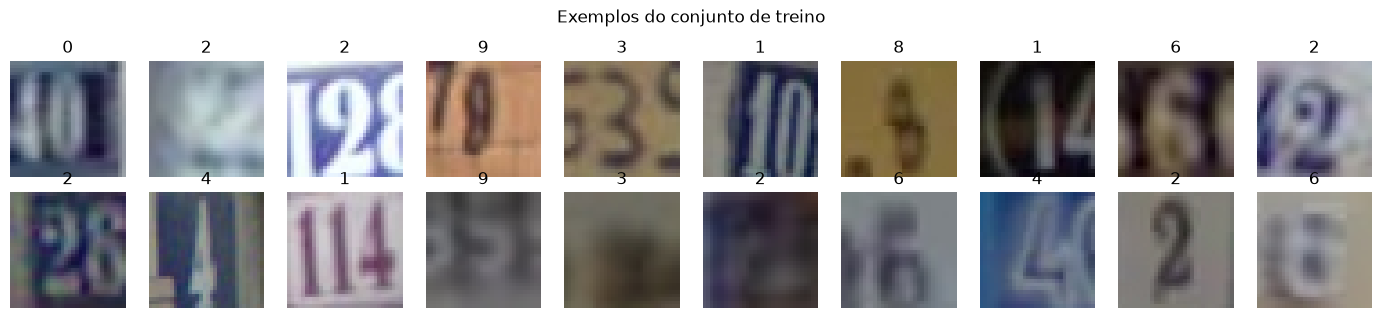

,treino,validação,teste
dígito,,,
0,4506,442,1744
1,12418,1443,5099
2,9475,1110,4149
3,7639,858,2882
4,6717,741,2523
5,6216,666,2384
6,5163,564,1977
7,5068,527,2019
8,4538,507,1660


In [3]:
fig, ax = plt.subplots(2, 10, figsize=(14, 3.2))
for i, a in enumerate(ax.flat):
    a.imshow(X_tr_u8[i].permute(1, 2, 0)); a.set_title(int(y_train[i])); a.axis('off')
plt.suptitle('Exemplos do conjunto de treino'); plt.tight_layout(); plt.savefig('resultados/exemplos.png', dpi=120); plt.show()

dist = pd.DataFrame({s: np.bincount(y.numpy(), minlength=10) for s, y in
                     [('treino', y_train), ('validação', y_val), ('teste', y_test)]})
dist.index.name = 'dígito'; dist

**Pré-processamento.** Duas versões dos dados:
- `bruto`: pixels em [0, 1] (como no notebook da aula, só `ToTensor`).
- `norm`: normalização por canal com média/desvio **calculados só no treino** (sem vazamento da validação/teste).

In [4]:
mean, std = L.compute_norm_stats(X_tr_u8)
print('média por canal:', mean.numpy().round(4), '| desvio:', std.numpy().round(4))
torch.save({'mean': mean, 'std': std}, 'pesos/normalizacao.pt')

DATA = {
    'bruto': dict(X_train=L.preprocess(X_tr_u8), y_train=y_train,
                  X_val=L.preprocess(X_va_u8), y_val=y_val,
                  X_test=L.preprocess(X_test_u8), y_test=y_test),
    'norm':  dict(X_train=L.preprocess(X_tr_u8, mean, std), y_train=y_train,
                  X_val=L.preprocess(X_va_u8, mean, std), y_val=y_val,
                  X_test=L.preprocess(X_test_u8, mean, std), y_test=y_test),
}

média por canal: [0.4376 0.4437 0.4727] | desvio: [0.1979 0.2009 0.1969]


## 2. Função que roda um experimento

Para cada experimento: fixa a semente, cria o modelo, treina registrando **loss e acurácia de treino e validação por época**,
guarda os pesos da melhor época na validação, mede a acurácia no teste e salva histórico (`resultados/*.json`), curva (`resultados/*.png`) e pesos (`pesos/*.pt`).

> A acurácia de treino é a média durante a época (com dropout/augmentation ativos); validação e teste são medidos com o modelo em modo `eval`.

In [5]:
RESULTS = []

def run(exp_id, nome, modificacao, make_model, dados='norm', **train_kw):
    print(f'=== E{exp_id}: {nome} ===')
    L.set_seed(SEED)
    model = make_model()
    data = DATA[dados]
    t0 = time.time()
    hist = L.train_model(model, data, seed=SEED, device=device, **train_kw)
    test_loss, test_acc = L.evaluate(model, data['X_test'], data['y_test'], device=device)
    b = hist['best_epoch']
    row = dict(exp=exp_id, nome=nome, modificacao=modificacao, dados=dados,
               params=L.count_params(model), epocas=train_kw['epochs'], melhor_epoca=b + 1,
               train_loss=hist['train_loss'][b], val_loss=hist['val_loss'][b],
               train_acc=hist['train_acc'][b], val_acc=hist['val_acc'][b],
               test_acc=test_acc, tempo_min=(time.time() - t0) / 60,
               config={k: v for k, v in train_kw.items()})
    RESULTS.append(row)
    torch.save({'state_dict': model.state_dict(), 'row': row}, f'pesos/E{exp_id}.pt')
    with open(f'resultados/E{exp_id}.json', 'w') as f:
        json.dump({'row': row, 'hist': hist}, f, indent=1)
    L.plot_history(hist, f'E{exp_id} — {nome}', f'resultados/E{exp_id}_curvas.png'); plt.show()
    print(f"melhor época {b+1}: val_acc={row['val_acc']:.4f} | test_acc={test_acc:.4f} | {row['tempo_min']:.1f} min")
    return model, hist

## 3. Experimentos

Cada experimento muda **uma coisa** em relação ao anterior (exceto E7 e E8, explicados abaixo), para dar para atribuir a melhora/piora.

### E1 — Classificador linear
`logits = x·W + b` sobre os 3072 pixels normalizados, cross-entropy + regularização L2 (weight decay), SGD com momentum — mesma ideia do classificador linear da aula, agora com `nn.Linear`.

=== E1: Classificador linear ===


época  1/20 | treino loss 2.2538 acc 0.2064 | val loss 2.2423 acc 0.2277 | 0.4s


época  2/20 | treino loss 2.2059 acc 0.2420 | val loss 2.2000 acc 0.2344 | 0.4s


época  3/20 | treino loss 2.1889 acc 0.2488 | val loss 2.2021 acc 0.2525 | 0.5s


época  4/20 | treino loss 2.1790 acc 0.2544 | val loss 2.2115 acc 0.2524 | 0.4s


época  5/20 | treino loss 2.1763 acc 0.2573 | val loss 2.1950 acc 0.2615 | 1.0s


... (11 outputs left out)

época 17/20 | treino loss 2.1517 acc 0.2709 | val loss 2.1614 acc 0.2785 | 1.5s


época 18/20 | treino loss 2.1510 acc 0.2693 | val loss 2.1659 acc 0.2804 | 1.5s


época 19/20 | treino loss 2.1473 acc 0.2756 | val loss 2.2512 acc 0.2506 | 1.5s


época 20/20 | treino loss 2.1509 acc 0.2712 | val loss 2.1720 acc 0.2832 | 1.5s


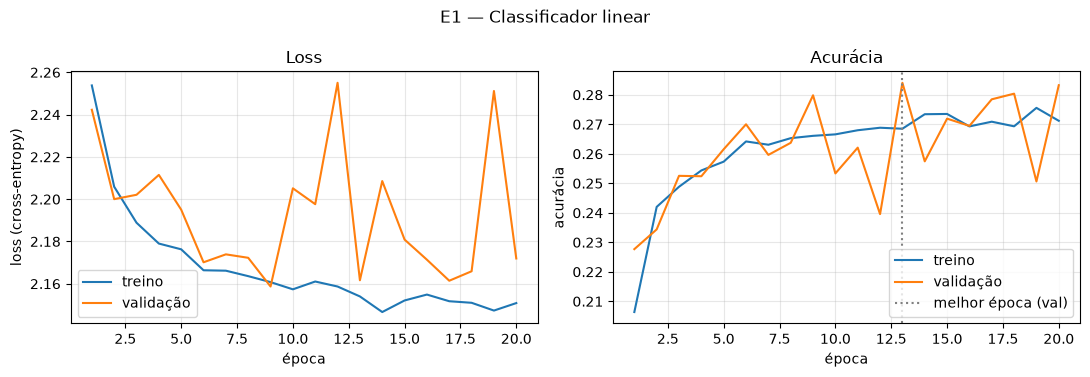

melhor época 13: val_acc=0.2841 | test_acc=0.2341 | 0.4 min


In [6]:
run(1, 'Classificador linear', 'Linear 3072→10, SGD+L2',
    lambda: L.LinearClassifier(), dados='norm',
    epochs=20, batch_size=128, lr=1e-3, optimizer='sgd', weight_decay=1e-4);

### E2 — MLP baseline (código da aula)
Exatamente a MLP do notebook da aula: 2 camadas ocultas de 500 neurônios, ReLU, Adam lr=1e-3, batch 100, entrada só em [0, 1].

=== E2: MLP baseline ===


época  1/25 | treino loss 2.1650 acc 0.2092 | val loss 2.0044 acc 0.2554 | 8.7s


época  2/25 | treino loss 1.8923 acc 0.3130 | val loss 1.6974 acc 0.4233 | 30.4s


época  3/25 | treino loss 1.5688 acc 0.4610 | val loss 1.5051 acc 0.4840 | 32.7s


época  4/25 | treino loss 1.4573 acc 0.5023 | val loss 1.4219 acc 0.5235 | 29.8s


época  5/25 | treino loss 1.4096 acc 0.5223 | val loss 1.4742 acc 0.5059 | 30.9s


... (16 outputs left out)

época 22/25 | treino loss 1.2772 acc 0.5811 | val loss 1.3142 acc 0.5684 | 30.4s


época 23/25 | treino loss 1.2736 acc 0.5820 | val loss 1.3306 acc 0.5620 | 29.8s


época 24/25 | treino loss 1.2701 acc 0.5857 | val loss 1.2923 acc 0.5786 | 29.7s


época 25/25 | treino loss 1.2677 acc 0.5844 | val loss 1.2986 acc 0.5710 | 29.4s


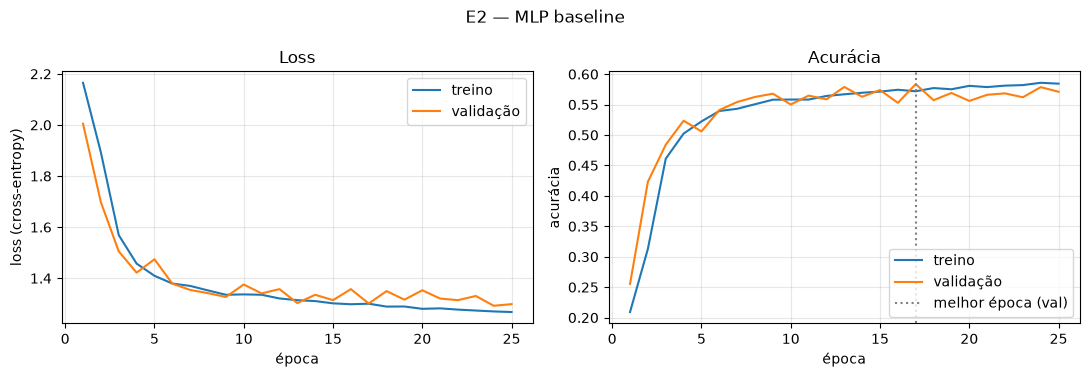

melhor época 17: val_acc=0.5835 | test_acc=0.5501 | 12.1 min


In [7]:
run(2, 'MLP baseline', 'MLP 2×500, entrada [0,1]',
    lambda: L.MLP([500, 500]), dados='bruto',
    epochs=25, batch_size=100, lr=1e-3);

### E3 — + normalização por canal

=== E3: MLP + normalização ===


época  1/25 | treino loss 1.1867 acc 0.6201 | val loss 0.9373 acc 0.7140 | 9.7s


época  2/25 | treino loss 0.8095 acc 0.7522 | val loss 0.7838 acc 0.7640 | 9.5s


época  3/25 | treino loss 0.7040 acc 0.7853 | val loss 0.7499 acc 0.7826 | 9.6s


época  4/25 | treino loss 0.6333 acc 0.8081 | val loss 0.7005 acc 0.7943 | 10.1s


época  5/25 | treino loss 0.5909 acc 0.8187 | val loss 0.6610 acc 0.8111 | 9.9s


... (16 outputs left out)

época 22/25 | treino loss 0.3122 acc 0.9010 | val loss 0.8849 acc 0.8220 | 9.7s


época 23/25 | treino loss 0.3138 acc 0.9009 | val loss 0.8298 acc 0.8243 | 9.8s


época 24/25 | treino loss 0.3007 acc 0.9065 | val loss 0.8388 acc 0.8230 | 10.4s


época 25/25 | treino loss 0.2890 acc 0.9093 | val loss 0.8296 acc 0.8306 | 10.2s


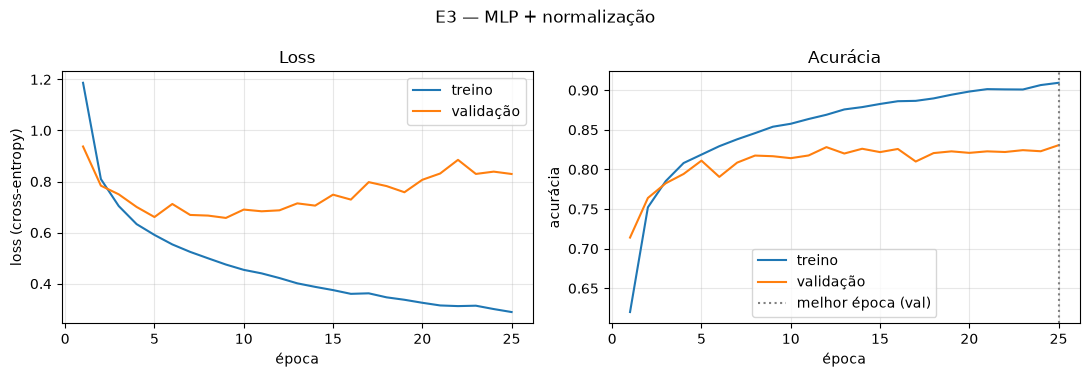

melhor época 25: val_acc=0.8306 | test_acc=0.7962 | 4.3 min


In [8]:
run(3, 'MLP + normalização', 'E2 + normalização média/desvio',
    lambda: L.MLP([500, 500]), dados='norm',
    epochs=25, batch_size=100, lr=1e-3);

### E4 — + mais camadas e neurônios (1024 → 512 → 256)

=== E4: MLP maior ===


época  1/25 | treino loss 1.2242 acc 0.5992 | val loss 0.9398 acc 0.7106 | 17.2s


época  2/25 | treino loss 0.8375 acc 0.7393 | val loss 0.8142 acc 0.7445 | 25.0s


época  3/25 | treino loss 0.7213 acc 0.7752 | val loss 0.7452 acc 0.7701 | 23.1s


época  4/25 | treino loss 0.6541 acc 0.7974 | val loss 0.6862 acc 0.7968 | 25.0s


época  5/25 | treino loss 0.6030 acc 0.8122 | val loss 0.6843 acc 0.8019 | 24.3s


... (16 outputs left out)

época 22/25 | treino loss 0.3319 acc 0.8954 | val loss 0.7565 acc 0.8348 | 27.8s


época 23/25 | treino loss 0.3207 acc 0.8997 | val loss 0.7955 acc 0.8238 | 26.2s


época 24/25 | treino loss 0.3278 acc 0.8964 | val loss 0.8191 acc 0.8236 | 28.2s


época 25/25 | treino loss 0.3106 acc 0.9020 | val loss 0.8026 acc 0.8257 | 26.5s


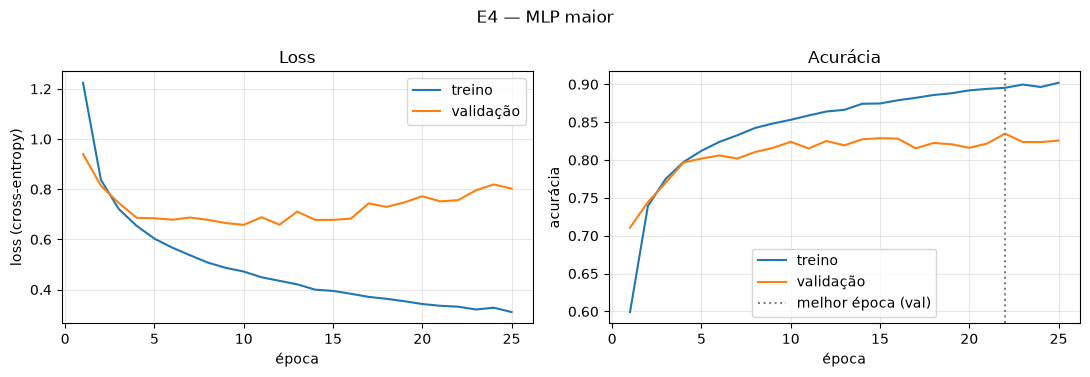

melhor época 22: val_acc=0.8348 | test_acc=0.7977 | 10.5 min


In [9]:
run(4, 'MLP maior', 'E3 com 3 camadas 1024-512-256',
    lambda: L.MLP([1024, 512, 256]), dados='norm',
    epochs=25, batch_size=100, lr=1e-3);

### E5 — + Dropout 0.3

=== E5: MLP + dropout ===


época  1/25 | treino loss 1.5364 acc 0.4804 | val loss 1.0973 acc 0.6628 | 21.7s


época  2/25 | treino loss 1.1435 acc 0.6424 | val loss 0.9140 acc 0.7243 | 27.7s


época  3/25 | treino loss 1.0428 acc 0.6759 | val loss 0.8813 acc 0.7405 | 27.6s


época  4/25 | treino loss 0.9835 acc 0.6963 | val loss 0.8453 acc 0.7468 | 27.5s


época  5/25 | treino loss 0.9323 acc 0.7121 | val loss 0.7952 acc 0.7624 | 26.8s


... (16 outputs left out)

época 22/25 | treino loss 0.7291 acc 0.7801 | val loss 0.6579 acc 0.8107 | 26.6s


época 23/25 | treino loss 0.7220 acc 0.7838 | val loss 0.6620 acc 0.8094 | 26.1s


época 24/25 | treino loss 0.7103 acc 0.7865 | val loss 0.6386 acc 0.8193 | 32.0s


época 25/25 | treino loss 0.7156 acc 0.7867 | val loss 0.6365 acc 0.8163 | 27.9s


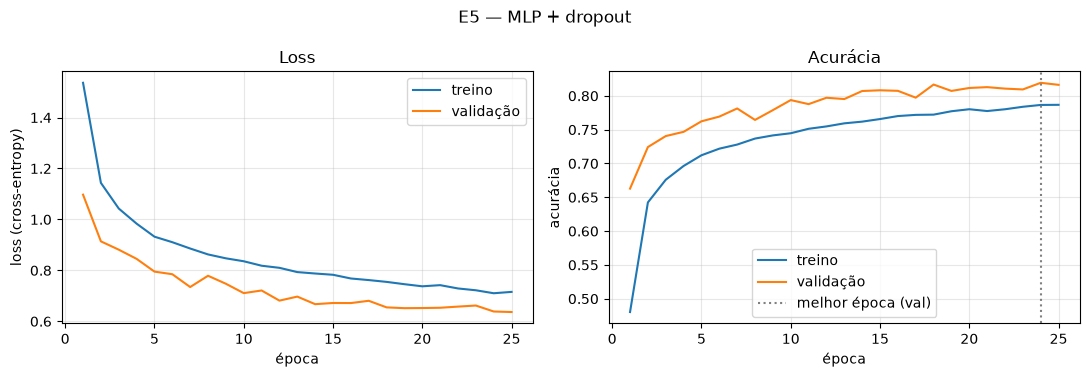

melhor época 24: val_acc=0.8193 | test_acc=0.7870 | 11.3 min


In [10]:
run(5, 'MLP + dropout', 'E4 + dropout 0.3',
    lambda: L.MLP([1024, 512, 256], dropout=0.3), dados='norm',
    epochs=25, batch_size=100, lr=1e-3);

### E6 — + Batch Normalization

=== E6: MLP + dropout + BN ===


época  1/25 | treino loss 1.4772 acc 0.4996 | val loss 1.0088 acc 0.6847 | 18.0s


época  2/25 | treino loss 1.0216 acc 0.6743 | val loss 0.7944 acc 0.7480 | 19.5s


época  3/25 | treino loss 0.8764 acc 0.7223 | val loss 0.7065 acc 0.7749 | 18.9s


época  4/25 | treino loss 0.8115 acc 0.7431 | val loss 0.6586 acc 0.7957 | 19.6s


época  5/25 | treino loss 0.7536 acc 0.7617 | val loss 0.6196 acc 0.8082 | 19.1s


... (16 outputs left out)

época 22/25 | treino loss 0.4666 acc 0.8503 | val loss 0.4288 acc 0.8717 | 20.0s


época 23/25 | treino loss 0.4599 acc 0.8541 | val loss 0.4307 acc 0.8692 | 19.5s


época 24/25 | treino loss 0.4492 acc 0.8567 | val loss 0.4347 acc 0.8721 | 23.1s


época 25/25 | treino loss 0.4429 acc 0.8576 | val loss 0.4310 acc 0.8709 | 23.1s


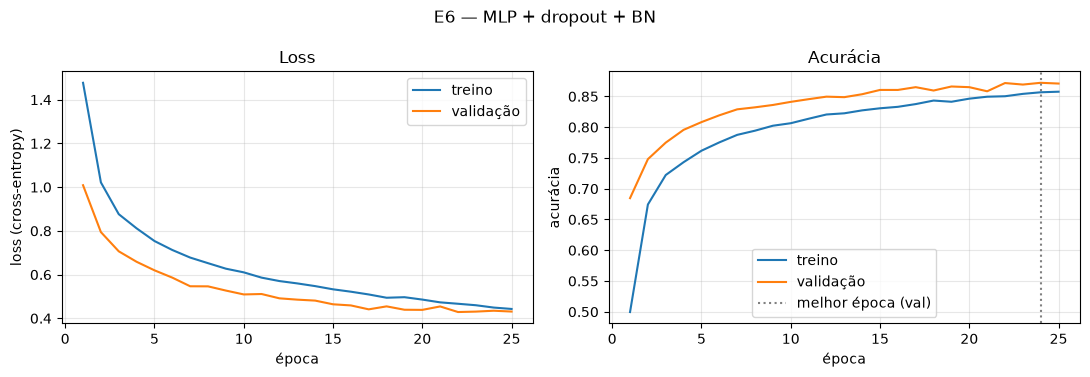

melhor época 24: val_acc=0.8721 | test_acc=0.8409 | 8.5 min


In [11]:
run(6, 'MLP + dropout + BN', 'E5 + BatchNorm',
    lambda: L.MLP([1024, 512, 256], dropout=0.3, batchnorm=True), dados='norm',
    epochs=25, batch_size=100, lr=1e-3);

### E7 — Otimização: batch 256 + taxa de aprendizado com decaimento cosseno
Batch maior dá passos menos ruidosos mas em menor número; o decaimento cosseno da lr compensa, permitindo passos grandes no começo e ajuste fino no fim.

=== E7: MLP batch 256 + cosine ===


época  1/25 | treino loss 1.5156 acc 0.4868 | val loss 1.0020 acc 0.6926 | 13.9s


época  2/25 | treino loss 1.0230 acc 0.6738 | val loss 0.7932 acc 0.7523 | 13.4s


época  3/25 | treino loss 0.8697 acc 0.7234 | val loss 0.7205 acc 0.7731 | 16.2s


época  4/25 | treino loss 0.7841 acc 0.7516 | val loss 0.6724 acc 0.7921 | 15.7s


época  5/25 | treino loss 0.7259 acc 0.7724 | val loss 0.6136 acc 0.8104 | 14.4s


... (16 outputs left out)

época 22/25 | treino loss 0.3500 acc 0.8897 | val loss 0.3952 acc 0.8793 | 15.3s


época 23/25 | treino loss 0.3471 acc 0.8893 | val loss 0.3945 acc 0.8803 | 15.4s


época 24/25 | treino loss 0.3409 acc 0.8926 | val loss 0.3928 acc 0.8792 | 14.9s


época 25/25 | treino loss 0.3390 acc 0.8928 | val loss 0.3941 acc 0.8791 | 16.4s


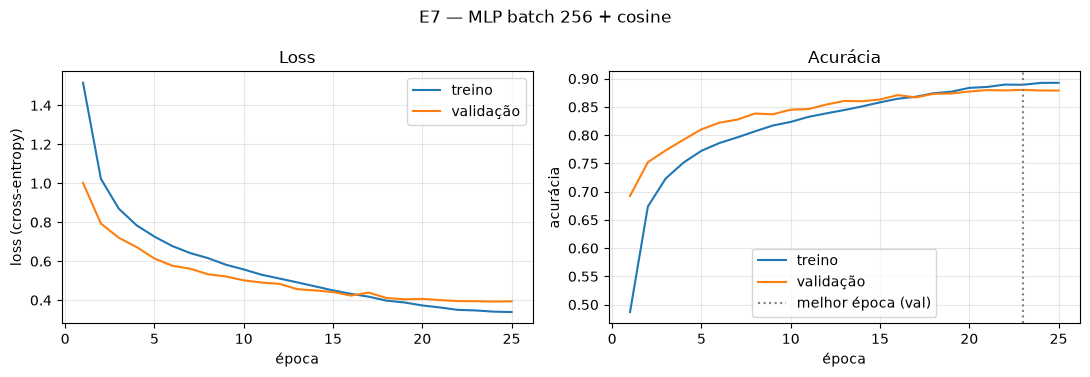

melhor época 23: val_acc=0.8803 | test_acc=0.8589 | 6.2 min


In [12]:
run(7, 'MLP batch 256 + cosine', 'E6 com batch 256 e lr cosseno',
    lambda: L.MLP([1024, 512, 256], dropout=0.3, batchnorm=True), dados='norm',
    epochs=25, batch_size=256, lr=1e-3, scheduler='cosine');

### E8 — CNN (rede convolucional) + data augmentation
O enunciado deixa a arquitetura livre e cita "número de filtros". A MLP trata cada pixel como uma entrada independente;
a convolução reaproveita os mesmos filtros em toda a imagem, o que é muito mais adequado a imagens.
3 blocos conv (32→64→128 filtros, BN, ReLU, max-pool) + classificador com dropout 0.3.
Augmentation: translação aleatória de até 2 px (sem flip, que altera dígitos). AdamW (weight decay 5e-4) + lr cosseno.

=== E8: CNN + augmentation ===


época  1/20 | treino loss 1.0238 acc 0.6561 | val loss 0.3360 acc 0.8975 | 200.8s


época  2/20 | treino loss 0.4479 acc 0.8661 | val loss 0.2769 acc 0.9181 | 170.4s


época  3/20 | treino loss 0.3672 acc 0.8938 | val loss 0.2407 acc 0.9277 | 156.7s


época  4/20 | treino loss 0.3213 acc 0.9092 | val loss 0.2104 acc 0.9376 | 155.3s


época  5/20 | treino loss 0.2929 acc 0.9180 | val loss 0.2224 acc 0.9382 | 154.1s


... (11 outputs left out)

época 17/20 | treino loss 0.1373 acc 0.9649 | val loss 0.1552 acc 0.9599 | 154.9s


época 18/20 | treino loss 0.1309 acc 0.9663 | val loss 0.1557 acc 0.9606 | 152.9s


época 19/20 | treino loss 0.1266 acc 0.9667 | val loss 0.1543 acc 0.9610 | 155.1s


época 20/20 | treino loss 0.1231 acc 0.9685 | val loss 0.1547 acc 0.9607 | 155.2s


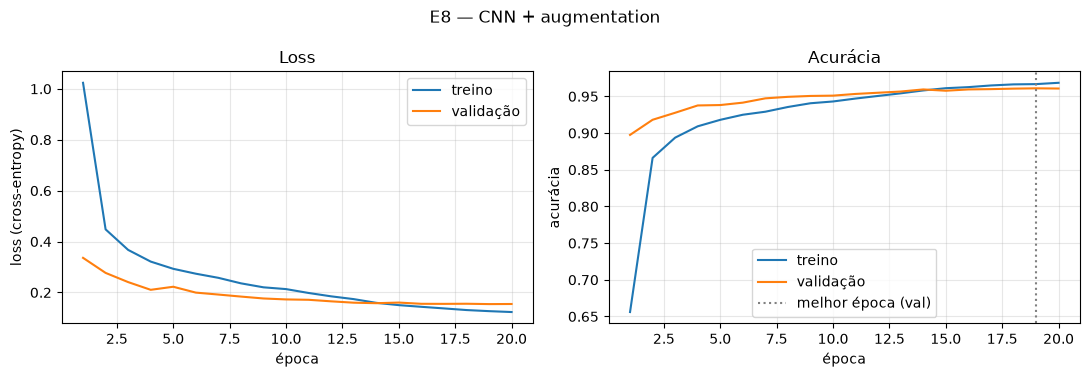

melhor época 19: val_acc=0.9610 | test_acc=0.9618 | 53.1 min


In [13]:
run(8, 'CNN + augmentation', 'CNN 3 blocos + translação ±2px',
    lambda: L.CNN(dropout=0.3), dados='norm',
    epochs=20, batch_size=128, lr=1e-3, optimizer='adamw', weight_decay=5e-4,
    scheduler='cosine', augment_shift=2);

## 4. Comparação dos experimentos

In [14]:
df = pd.DataFrame(RESULTS).drop(columns=['config'])
df['gap_treino_val'] = df['train_acc'] - df['val_acc']
df.to_csv('resultados/tabela_experimentos.csv', index=False)
fmt = {c: '{:.4f}' for c in ['train_loss', 'val_loss', 'train_acc', 'val_acc', 'test_acc', 'gap_treino_val']}
df.style.format(fmt | {'tempo_min': '{:.1f}', 'params': '{:,}'})

,exp,nome,modificacao,dados,params,epocas,melhor_epoca,train_loss,val_loss,train_acc,val_acc,test_acc,tempo_min,gap_treino_val
0,1,Classificador linear,"Linear 3072→10, SGD+L2",norm,"30,730",20,13,2.1540,2.1617,0.2685,0.2841,0.2341,0.4,-0.0156
1,2,MLP baseline,"MLP 2×500, entrada [0,1]",bruto,"1,792,010",25,17,1.3004,1.3011,0.5719,0.5835,0.5501,12.1,-0.0117
2,3,MLP + normalização,E2 + normalização média/desvio,norm,"1,792,010",25,25,0.2890,0.8296,0.9093,0.8306,0.7962,4.3,0.0787
3,4,MLP maior,E3 com 3 camadas 1024-512-256,norm,"3,805,450",25,22,0.3319,0.7565,0.8954,0.8348,0.7977,10.5,0.0606
4,5,MLP + dropout,E4 + dropout 0.3,norm,"3,805,450",25,24,0.7103,0.6386,0.7865,0.8193,0.7870,11.3,-0.0327
5,6,MLP + dropout + BN,E5 + BatchNorm,norm,"3,809,034",25,24,0.4492,0.4347,0.8567,0.8721,0.8409,8.5,-0.0154
6,7,MLP batch 256 + cosine,E6 com batch 256 e lr cosseno,norm,"3,809,034",25,23,0.3471,0.3945,0.8893,0.8803,0.8589,6.2,0.0090
7,8,CNN + augmentation,CNN 3 blocos + translação ±2px,norm,"814,570",20,19,0.1266,0.1543,0.9667,0.9610,0.9618,53.1,0.0057


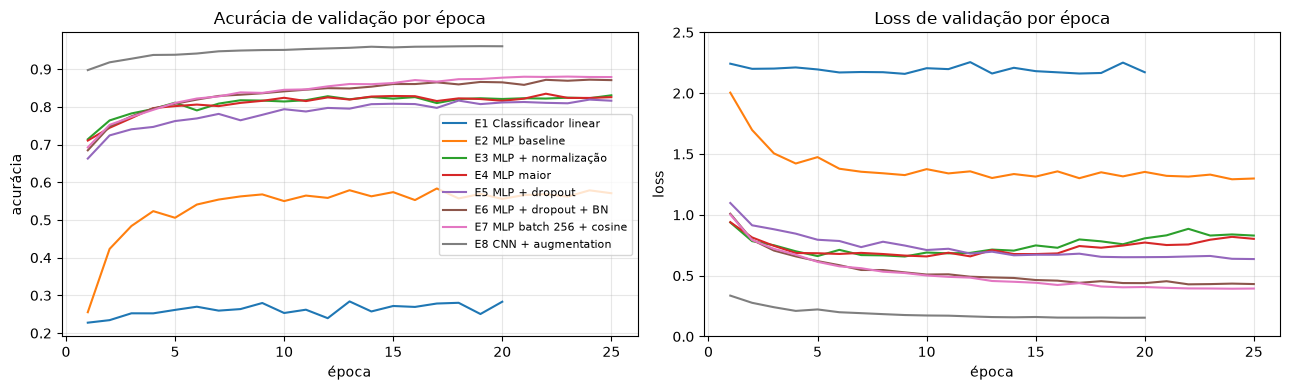

In [15]:
fig, ax = plt.subplots(1, 2, figsize=(13, 4))
for r in RESULTS:
    h = json.load(open(f"resultados/E{r['exp']}.json"))['hist']
    ax[0].plot(range(1, len(h['val_acc']) + 1), h['val_acc'], label=f"E{r['exp']} {r['nome']}")
    ax[1].plot(range(1, len(h['val_loss']) + 1), h['val_loss'], label=f"E{r['exp']}")
ax[0].set(title='Acurácia de validação por época', xlabel='época', ylabel='acurácia')
ax[1].set(title='Loss de validação por época', xlabel='época', ylabel='loss', ylim=(0, 2.5))
for a in ax: a.grid(alpha=.3)
ax[0].legend(fontsize=8); plt.tight_layout(); plt.savefig('resultados/comparacao_validacao.png', dpi=130); plt.show()

## 5. Escolha do modelo final
Critério: **maior acurácia de validação** (o teste não participa da escolha).

In [16]:
best = max(RESULTS, key=lambda r: r['val_acc'])
print(f"Modelo escolhido: E{best['exp']} — {best['nome']}")
print(f"val_acc = {best['val_acc']:.4f} | test_acc = {best['test_acc']:.4f} | época {best['melhor_epoca']}")

ckpt = torch.load(f"pesos/E{best['exp']}.pt")
torch.save({'exp': best['exp'], 'nome': best['nome'], 'state_dict': ckpt['state_dict'],
            'mean': mean, 'std': std, 'row': best}, 'melhor_modelo.pt')
with open('resultados/melhor_modelo.json', 'w') as f:
    json.dump(best, f, indent=1)
print('pesos salvos em melhor_modelo.pt')

Modelo escolhido: E8 — CNN + augmentation
val_acc = 0.9610 | test_acc = 0.9618 | época 19
pesos salvos em melhor_modelo.pt


## 6. Predição do conjunto adicional
Feita **somente agora**, com o modelo já escolhido e congelado. Pré-processamento idêntico ao do treino (mesma média/desvio).
As imagens são lidas em **ordem natural do nome do arquivo** (`2.png` antes de `10.png`), e o arquivo sai com um inteiro (0–9) por linha.

Coloque as imagens do professor em `extra/` (descompacte o zip ali) e ajuste `NOMES` abaixo.

In [17]:
NOMES = 'NOME1_NOME2'          # <- troque pelos nomes do grupo
PASTA_EXTRA = 'extra'

MODELOS = {1: lambda: L.LinearClassifier(), 2: lambda: L.MLP([500, 500]), 3: lambda: L.MLP([500, 500]),
           4: lambda: L.MLP([1024, 512, 256]), 5: lambda: L.MLP([1024, 512, 256], dropout=0.3),
           6: lambda: L.MLP([1024, 512, 256], dropout=0.3, batchnorm=True),
           7: lambda: L.MLP([1024, 512, 256], dropout=0.3, batchnorm=True), 8: lambda: L.CNN(dropout=0.3)}

final = torch.load('melhor_modelo.pt')
model = MODELOS[final['exp']]().to(device)
model.load_state_dict(final['state_dict'])
usa_norm = final['row']['dados'] == 'norm'

if os.path.isdir(PASTA_EXTRA):
    nomes_arq, X_extra_u8 = L.load_image_folder(PASTA_EXTRA)
    X_extra = L.preprocess(X_extra_u8, final['mean'], final['std']) if usa_norm else L.preprocess(X_extra_u8)
    preds = L.predict(model, X_extra, device=device)
    saida = f'{NOMES}_RESULTS.txt'
    L.write_results(preds, saida)
    print(f'{len(preds)} imagens -> {saida}')
    print('primeiros arquivos:', nomes_arq[:5], '... último:', nomes_arq[-1])
    print('distribuição das predições:', np.bincount(preds.numpy(), minlength=10))
else:
    print(f'Pasta {PASTA_EXTRA}/ não encontrada — baixe o conjunto adicional e rode esta célula de novo.')

203856 imagens -> NOME1_NOME2_RESULTS.txt
primeiros arquivos: ['000000.png', '000001.png', '000002.png', '000003.png', '000004.png'] ... último: 203855.png
distribuição das predições: [20306 21520 20671 20313 20252 20345 20164 20215 19958 20112]
